# Part 2: Single Stock Analysis Notebook


In [1]:
from contextlib import closing
from pathlib import Path
import json
import sqlite3

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

plt.style.use('seaborn-v0_8-whitegrid')


### 2.1 Parameters

At the top of the notebook, define these parameters using a Papermill-compatible cell:

- `ticker = "AAPL"` — Stock ticker to analyze
- `start_date = "2024-01-01"` — Analysis start date
- `end_date = "2024-12-31"` — Analysis end date

Tag the parameter cell as `parameters` in Jupyter. In JupyterLab, use Property Inspector → Cell Tags and verify the metadata tag is present; a `# Parameters` comment alone is insufficient. The `db_path` parameter points to the local homework database for portability.


In [2]:
ticker = "AAPL"  # Stock ticker to analyze
start_date = "2024-01-01"  # Analysis start date
end_date = "2024-12-31"  # Analysis end date
db_path = "data/data.db"  # Local homework database


In [3]:
# Parameters
ticker = "AAPL"
start_date = "2024-06-01"
end_date = "2024-11-30"
db_path = "/Users/philipsyan/Desktop/Pre-MFE Python/github_work/UCB-MFE-python-preprogram-2026-winter/Homeworks/HW2/Xiaofei_Yan/data/data.db"


### 2.2 Data Loading

- Load cleaned data for the specified ticker and date range
- Display summary: `"{Ticker} from {start} to {end}: {N} trading days"`
- Show the first and last few rows and actual first/last observation dates. Validate the input and report insufficient history clearly; 20 returns require at least 21 prices.

Each report shows its actual first and last observation dates. If a stock has a shorter history than the requested window, its metrics use only the dates it has; comparisons with full-window reports are therefore not like-for-like. Trailing prices are never extrapolated.


In [4]:
# Validate the inputs before querying the cleaned homework table.
if not isinstance(ticker, str) or not ticker.strip():
    raise ValueError('ticker must be a non-empty stock symbol.')
report_ticker = ticker.strip().upper()

try:
    start_bound = pd.Timestamp(start_date)
    end_bound = pd.Timestamp(end_date)
except (TypeError, ValueError) as error:
    raise ValueError('start_date and end_date must be valid dates.') from error
if pd.isna(start_bound) or pd.isna(end_bound):
    raise ValueError('start_date and end_date must be valid dates.')
if start_bound > end_bound:
    raise ValueError('start_date must be on or before end_date.')
start_sql = start_bound.strftime('%Y-%m-%d')
end_sql = end_bound.strftime('%Y-%m-%d')

database = Path(db_path).expanduser().resolve()
if not database.is_file():
    raise FileNotFoundError(f'Local homework database not found: {database}')

query = """
SELECT ts, open, high, low, close, adj_close, volume
FROM ohlc_hw_cleaned
WHERE ticker = ? AND ts >= ? AND ts <= ?
ORDER BY ts
"""
with closing(sqlite3.connect(database.as_uri() + '?mode=ro', uri=True)) as connection:
    table_names = pd.read_sql_query(
        "SELECT name FROM sqlite_master WHERE type='table'",
        connection,
    )['name'].tolist()
    if 'ohlc_hw_cleaned' not in table_names:
        raise ValueError('Table ohlc_hw_cleaned is missing; complete Part 1 validation first.')
    df = pd.read_sql_query(
        query,
        connection,
        params=(report_ticker, start_sql, end_sql),
        parse_dates=['ts'],
    ).set_index('ts').sort_index()

if df.empty:
    raise ValueError(
        f'No cleaned observations found for {report_ticker} from {start_sql} to {end_sql}.'
    )
if df.index.has_duplicates:
    raise ValueError(f'{report_ticker} has duplicate dates in ohlc_hw_cleaned.')

print(f'{report_ticker} from {start_sql} to {end_sql}: {len(df)} trading days')
print(f'Actual observations: {df.index.min().date()} to {df.index.max().date()}')
display(df.head())
display(df.tail())

minimum_prices_for_20_returns = 21
if len(df) < minimum_prices_for_20_returns:
    print(
        f'Insufficient history for a full 20-return window: found {len(df)} prices; '
        f'at least {minimum_prices_for_20_returns} prices are required. '
        'The available rows are shown; 20-day rolling volatility will be unavailable.'
    )


AAPL from 2024-06-01 to 2024-11-30: 97 trading days
Actual observations: 2024-06-03 to 2024-10-18


,open,high,low,close,adj_close,volume
ts,,,,,,
2024-06-03,192.90,194.99,192.52,194.03,193.81,50080539
2024-06-04,194.64,195.32,193.03,194.35,194.13,47471445
2024-06-05,195.40,196.90,194.87,195.87,195.64,54156785
2024-06-06,195.69,196.50,194.17,194.48,194.26,41181753
2024-06-07,194.65,196.94,194.14,196.89,196.66,53103912


,open,high,low,close,adj_close,volume
ts,,,,,,
2024-10-14,228.70,231.73,228.60,231.30,231.30,39882100
2024-10-15,233.61,237.49,232.37,233.85,233.85,64751400
2024-10-16,231.60,232.12,229.84,231.78,231.78,34082240
2024-10-17,233.43,233.85,230.52,232.15,232.15,32993810
2024-10-18,236.18,236.18,234.01,235.00,235.00,45441281


### 2.3 Calculate Risk Metrics

Implement functions to calculate:

#### Daily Returns

Calculate daily log returns using `np.log(prices / prices.shift(1))`.

#### Rolling Volatility (20-day window)

Calculate annualized rolling volatility using `returns.rolling(window).std() * np.sqrt(252)`.

#### Drawdown and Maximum Drawdown

Return per-date drawdown from the running price peak. The maximum drawdown for a summary is `drawdown.min()`; the running worst drawdown is `drawdown.cummin()`.

#### Sharpe Ratio

Calculate the annualized Sharpe ratio using the course approximation and a 2% annual risk-free rate.

Use adjusted close for report returns and drawdown. Use daily log returns for volatility and Sharpe. Return `NaN` for zero volatility or insufficient returns. Keep values as fractions in calculations and format percentages only for display.


In [5]:
def calculate_returns(prices: pd.Series) -> pd.Series:
    """Calculate daily log returns from an adjusted price series."""
    return np.log(prices / prices.shift(1))


def calculate_volatility(returns: pd.Series, window: int = 20) -> pd.Series:
    """Calculate annualized rolling volatility from daily returns."""
    if not isinstance(window, int) or isinstance(window, bool) or window < 1:
        raise ValueError('window must be a positive integer.')
    return returns.rolling(window).std() * np.sqrt(252)


def calculate_max_drawdown(prices: pd.Series) -> pd.Series:
    """Return per-date drawdown from the running adjusted-price peak."""
    running_peak = prices.cummax()
    return (prices - running_peak) / running_peak


def calculate_sharpe_ratio(returns: pd.Series, risk_free_rate: float = 0.02) -> float:
    """Calculate the annualized Sharpe ratio using the course approximation."""
    observed = returns.dropna()
    std_return = observed.std(ddof=1)
    if len(observed) < 2 or not np.isfinite(std_return) or np.isclose(std_return, 0):
        return np.nan
    mean_return = observed.mean()
    return (mean_return * 252 - risk_free_rate) / (std_return * np.sqrt(252))


# Apply the report functions to adjusted close prices.
df['log_return'] = calculate_returns(df['adj_close'])
df['volatility'] = calculate_volatility(df['log_return'], window=20)
df['drawdown'] = calculate_max_drawdown(df['adj_close'])
sharpe_ratio = calculate_sharpe_ratio(df['log_return'], risk_free_rate=0.02)

display(df[['adj_close', 'log_return', 'volatility', 'drawdown']].tail())
if np.isfinite(sharpe_ratio):
    print(f'Sharpe Ratio: {sharpe_ratio:.2f}')
else:
    print('Sharpe Ratio: N/A (insufficient returns or zero volatility)')


,adj_close,log_return,volatility,drawdown
ts,,,,
2024-10-14,231.30,0.016346,0.242503,-0.013856
2024-10-15,233.85,0.010964,0.243942,-0.002984
2024-10-16,231.78,-0.008891,0.241973,-0.011810
2024-10-17,232.15,0.001595,0.206097,-0.010232
2024-10-18,235.00,0.012202,0.209521,0.000000


Sharpe Ratio: 1.91


### 2.4 Visualization

Create a **2x2 subplot grid** showing:

**Top Left - Price Chart:**

- Plot adjusted close prices
- Add a 50-day moving average
- Color the line by volatility (high vol = red, low vol = green)
  - Use mean rolling volatility over the report as the threshold; gray indicates unavailable warm-up estimates. Equal-to-mean can be green. This is retrospective coloring.
- Title: `"{Ticker} Price and 50-day MA"`

**Top Right - Daily Returns:**

- Bar chart of daily returns
- Color bars: green (positive), red (negative)
- Add horizontal line at 0
- Title: `"{Ticker} Daily Returns"`

**Bottom Left - Rolling Volatility:**

- Line chart of 20-day rolling volatility
- Add horizontal line at mean volatility
- Shade regions: high vol (>mean), low vol (<mean)
- Title: `"{Ticker} Rolling Volatility (20-day)"`

**Bottom Right - Drawdown:**

- Area chart of per-date drawdown (fill below 0)
- Color: red/pink gradient
- Mark the maximum drawdown point
- Title: `"{Ticker} Maximum Drawdown"`

**Requirements:**

- Figure size: 16x12 inches
- Add grid to all plots
- Label axes properly
- Use consistent color scheme
- Add a main title: `"{Ticker} Risk Analysis Report - {start_date} to {end_date}"`

Preserve rolling warm-up gaps; do not fill them with zero. A 50-day moving average is unavailable until 50 prices exist. If a report has fewer observations, show the available data and explain the missing average. Layered transparent red fills are sufficient for the gradient.

Make it pretty :)


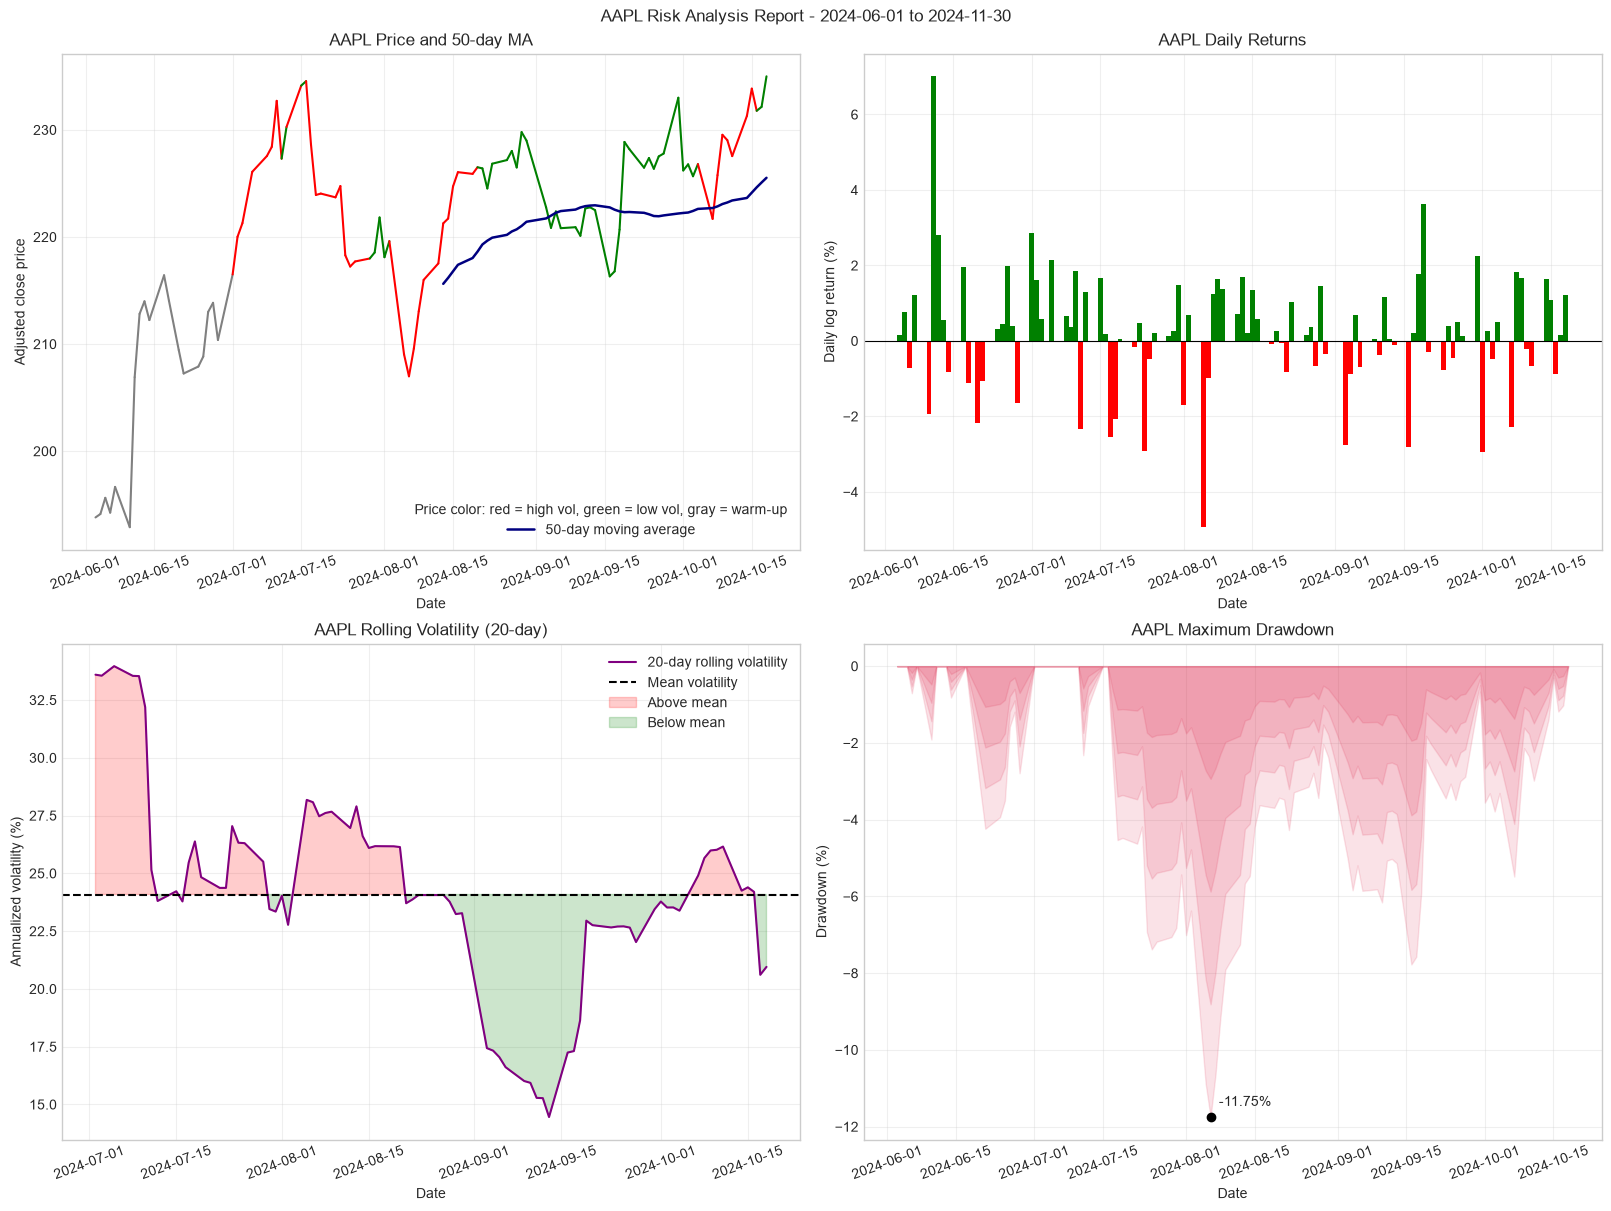

In [6]:
# The 50-day average remains missing until a full 50-price window is available.
df['sma_50'] = df['adj_close'].rolling(window=50).mean()
mean_volatility = df['volatility'].mean()

fig, axes = plt.subplots(2, 2, figsize=(16, 12), layout='constrained')
fig.suptitle(f'{report_ticker} Risk Analysis Report - {start_date} to {end_date}')

# Top left: adjusted close segments use the ending date's rolling volatility.
for i in range(1, len(df)):
    volatility = df['volatility'].iloc[i]
    if pd.isna(volatility) or pd.isna(mean_volatility):
        color = 'gray'
    elif volatility > mean_volatility:
        color = 'red'
    else:
        color = 'green'
    axes[0, 0].plot(df.index[i-1:i+1], df['adj_close'].iloc[i-1:i+1], color=color)
if len(df) == 1:
    axes[0, 0].plot(df.index, df['adj_close'], color='gray', marker='o')
axes[0, 0].plot(df.index, df['sma_50'], color='navy', linewidth=1.8, label='50-day moving average')
axes[0, 0].set(title=f'{report_ticker} Price and 50-day MA', xlabel='Date', ylabel='Adjusted close price')
axes[0, 0].legend(title='Price color: red = high vol, green = low vol, gray = warm-up')
if df['sma_50'].notna().sum() == 0:
    axes[0, 0].text(
        0.02, 0.03, f'50-day MA unavailable: {len(df)} prices; 50 required.',
        transform=axes[0, 0].transAxes, fontsize=9,
    )

# Top right: daily log returns are displayed as percentages.
return_colors = np.where(df['log_return'].ge(0), 'green', 'red')
axes[0, 1].bar(df.index, df['log_return'] * 100, width=1, color=return_colors)
axes[0, 1].axhline(0, color='black', linewidth=0.8)
axes[0, 1].set(title=f'{report_ticker} Daily Returns', xlabel='Date', ylabel='Daily log return (%)')

# Bottom left: preserve the rolling-window warm-up NaNs.
volatility_pct = df['volatility'] * 100
axes[1, 0].plot(df.index, volatility_pct, color='purple', label='20-day rolling volatility')
if np.isfinite(mean_volatility):
    mean_volatility_pct = mean_volatility * 100
    axes[1, 0].axhline(mean_volatility_pct, color='black', linestyle='--', label='Mean volatility')
    axes[1, 0].fill_between(
        df.index, volatility_pct, mean_volatility_pct,
        where=df['volatility'].gt(mean_volatility), color='red', alpha=0.2, interpolate=True,
        label='Above mean',
    )
    axes[1, 0].fill_between(
        df.index, volatility_pct, mean_volatility_pct,
        where=df['volatility'].lt(mean_volatility), color='green', alpha=0.2, interpolate=True,
        label='Below mean',
    )
else:
    axes[1, 0].text(
        0.02, 0.95, '20-day volatility unavailable: need at least 21 prices.',
        transform=axes[1, 0].transAxes, va='top', fontsize=9,
    )
axes[1, 0].set(
    title=f'{report_ticker} Rolling Volatility (20-day)',
    xlabel='Date', ylabel='Annualized volatility (%)',
)
axes[1, 0].legend()

# Bottom right: layered transparent fills create the red/pink drawdown gradient.
drawdown_pct = df['drawdown'] * 100
for fraction, alpha in [(1.0, 0.12), (0.75, 0.12), (0.5, 0.12), (0.25, 0.12)]:
    axes[1, 1].fill_between(df.index, drawdown_pct * fraction, 0, color='crimson', alpha=alpha)
maximum_drawdown_date = df['drawdown'].idxmin()
maximum_drawdown_pct = drawdown_pct.loc[maximum_drawdown_date]
axes[1, 1].scatter([maximum_drawdown_date], [maximum_drawdown_pct], color='black', zorder=3)
axes[1, 1].annotate(
    f'{maximum_drawdown_pct:.2f}%',
    (maximum_drawdown_date, maximum_drawdown_pct),
    xytext=(6, 8), textcoords='offset points',
)
axes[1, 1].set(
    title=f'{report_ticker} Maximum Drawdown',
    xlabel='Date', ylabel='Drawdown (%)',
)

for ax in axes.flat:
    ax.grid(True, alpha=0.3)
    ax.tick_params(axis='x', labelrotation=20)

plt.show()


### 2.5 Summary Statistics Table

Summarize the full-period return and risk metrics. Annualized return compounds the nonmissing daily log returns; annualized volatility uses the sample standard deviation of those same returns. Positive days use all nonmissing returns as the denominator, including zero-return days. Empty up-day or down-day groups display `N/A`.


In [7]:
# Use all nonmissing daily log returns for the period-level return statistics.
summary_prices = df['adj_close'].dropna()
summary_returns = df['log_return'].dropna()
number_of_returns = len(summary_returns)

if not summary_prices.empty:
    total_return = summary_prices.iloc[-1] / summary_prices.iloc[0] - 1
else:
    total_return = np.nan

if number_of_returns > 0:
    annualized_return = np.exp(summary_returns.sum() * 252 / number_of_returns) - 1
else:
    annualized_return = np.nan

if number_of_returns >= 2:
    annualized_volatility = summary_returns.std(ddof=1) * np.sqrt(252)
else:
    annualized_volatility = np.nan

if number_of_returns > 0:
    positive_days = summary_returns.gt(0).sum() / number_of_returns
else:
    positive_days = np.nan

up_day_returns = summary_returns.loc[summary_returns.gt(0)]
down_day_returns = summary_returns.loc[summary_returns.lt(0)]
maximum_drawdown = df['drawdown'].min()
best_day = summary_returns.max() if number_of_returns else np.nan
worst_day = summary_returns.min() if number_of_returns else np.nan
average_up_day = up_day_returns.mean() if not up_day_returns.empty else np.nan
average_down_day = down_day_returns.mean() if not down_day_returns.empty else np.nan


def format_percentage(value, decimals=2, signed=False):
    """Format a fractional value as a percentage, or show N/A if unavailable."""
    if not np.isfinite(value):
        return 'N/A'
    if signed:
        return f'{value:+.{decimals}%}'
    return f'{value:.{decimals}%}'


summary_table = pd.DataFrame({
    'Metric': [
        'Total Return',
        'Annualized Return',
        'Annualized Volatility',
        'Sharpe Ratio',
        'Maximum Drawdown',
        'Best Day',
        'Worst Day',
        'Positive Days',
        'Average Up Day',
        'Average Down Day',
    ],
    'Value': [
        format_percentage(total_return, signed=True),
        format_percentage(annualized_return, signed=True),
        format_percentage(annualized_volatility),
        f'{sharpe_ratio:.2f}' if np.isfinite(sharpe_ratio) else 'N/A',
        format_percentage(maximum_drawdown, signed=True),
        format_percentage(best_day, signed=True),
        format_percentage(worst_day, signed=True),
        format_percentage(positive_days, decimals=1),
        format_percentage(average_up_day, signed=True),
        format_percentage(average_down_day, signed=True),
    ],
})

display(summary_table)


def json_number(value):
    """Convert a finite scalar to a JSON number and unavailable values to null."""
    if value is None or not np.isfinite(value):
        return None
    return float(value)


report_metrics = {
    'ticker': report_ticker,
    'start_date': start_sql,
    'end_date': end_sql,
    'actual_start_date': df.index.min().strftime('%Y-%m-%d'),
    'actual_end_date': df.index.max().strftime('%Y-%m-%d'),
    'trading_days': int(len(df)),
    'avg_daily_return': json_number(summary_returns.mean()),
    'avg_volatility': json_number(df['volatility'].mean()),
    'max_drawdown': json_number(maximum_drawdown),
    'sharpe_ratio': json_number(sharpe_ratio),
    'total_return': json_number(total_return),
}
print('HW2_METRICS_JSON=' + json.dumps(report_metrics, allow_nan=False, sort_keys=True))


,Metric,Value
0,Total Return,+21.25%
1,Annualized Return,+65.84%
2,Annualized Volatility,25.45%
3,Sharpe Ratio,1.91
4,Maximum Drawdown,-11.75%
5,Best Day,+7.01%
6,Worst Day,-4.94%
7,Positive Days,62.5%
8,Average Up Day,+1.09%
9,Average Down Day,-1.28%


HW2_METRICS_JSON={"actual_end_date": "2024-10-18", "actual_start_date": "2024-06-03", "avg_daily_return": 0.002007366837828156, "avg_volatility": 0.240840098800071, "end_date": "2024-11-30", "max_drawdown": -0.11750159880622468, "sharpe_ratio": 1.9087206244573933, "start_date": "2024-06-01", "ticker": "AAPL", "total_return": 0.21252773334709252, "trading_days": 97}
